<a href="https://colab.research.google.com/github/sivasai-jonnadula/docs/blob/main/CN7031_Week5_SparkDF_Template.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CN7031 · Week 5 — Apache Spark: DataFrames and Spark SQL

---

**Practical lab workbook | Big Data Analytics (CN7031) 2026-27**
**Dr Fahimeh Jafari** : [F.Jafari@uel.ac.uk](mailto:F.Jafari@uel.ac.uk)

---

### Learning outcomes
By the end of this lab, you should be able to:
1. Run **Apache Spark** (PySpark) in Google Colab and start a **SparkSession**.
2. Load a CSV file into a Spark **DataFrame** and inspect its structure.
3. Use **DataFrame operations**: `select`, `filter`, `groupBy`, `orderBy`, `agg` and `withColumn`.
4. Explain **transformations, actions and lazy evaluation**.
5. Analyse data with **Spark SQL** queries on a temporary view.
6. **Visualise** query results in Python with pandas and Matplotlib.

### What is Spark?
In Week 4, Hive turned SQL into **MapReduce** jobs. MapReduce writes every intermediate result to disk, so a job with several steps reads and writes the disk again and again. **Apache Spark** does the same kind of distributed processing, but keeps intermediate data **in memory** and plans a whole chain of steps at once. For multi-step and repeated work it is often many times faster, and it is now the most widely used engine for big-data processing.

| Term | Meaning |
| :-- | :-- |
| **SparkSession** | Your connection to Spark: every DataFrame and SQL query starts from it (the variable `spark`) |
| **DataFrame** | A distributed table with named columns and types, split into **partitions** that are processed in parallel |
| **Transformation** | An operation that describes a new DataFrame, such as `select`, `filter` or `groupBy`. It runs **nothing** yet |
| **Action** | An operation that needs a result, such as `show`, `count` or `toPandas`. It makes Spark run the plan |
| **Spark SQL** | Lets you query DataFrames with SQL; SQL and DataFrame code compile to the **same** plan |

### The dataset
**FIFA 18 Complete Player Dataset**: about 18,000 football players from the video game FIFA 18, with 75 columns: name, age, nationality, club, ratings (overall and potential), market value, wage, and 34 skill attributes such as *Acceleration*, *Dribbling* and *Long shots*.

### How to use the notebook
- Use **Google Colab → Python 3 → CPU**. Run the cells in order, starting from Section 1. On a fresh runtime, Section 1 takes about 2–3 minutes.
- Download `CompleteDataset.csv` from Moodle before you start; you upload it in Step 1.2.
- An optional **extra lab** on unstructured data in Hadoop is in a separate notebook, `CN7031_Week5_Extra_StudentVersion.ipynb`, for those who want to go further.
- The code cells are **Python**. Each one starts with a comment line (`#`) that says what it does.
- Spark runs in **local mode** on this one Colab VM: the same code would run unchanged on a cluster of hundreds of machines.

**Important:** Colab storage is temporary and is deleted when its runtime resets. If that happens, run Section 1 again and upload the file again.

## 1. Getting ready

**Goal:** Install Spark, upload the data, and start a SparkSession.

### 1.1 Install Java and Spark

**Goal:** Spark is written in Scala and runs on the **Java Virtual Machine**, so it needs Java. **PySpark** is the Python package that contains Spark itself and lets you drive it from Python. This cell installs Java 17 and PySpark 4.0.4.

**Expected output:** a line starting `openjdk version "17…`, then `PySpark 4.0.4 is installed ✓  Java 17 is ready ✓`.

In [1]:
# @title ▶ 1.1 Install Java 17 and Apache Spark (PySpark 4.0.4)
# Import the tools used to run installation commands and check the result.
import os
import subprocess
import sys
from pathlib import Path

# Spark runs on the Java Virtual Machine; Spark 4 needs Java 17 or newer.
SPARK_VERSION = '4.0.4'
JAVA = Path('/usr/lib/jvm/java-17-openjdk-amd64')

# Run a system command and stop with a useful error if it fails.
def checked(args, timeout=900):
    p = subprocess.run(args, text=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, timeout=timeout)
    if p.returncode:
        raise RuntimeError(p.stdout[-5000:])
    return p.stdout

# Install Java 17 only when it is not already on this VM.
if not (JAVA / 'bin/java').exists():
    print('Installing Java 17 …')
    checked(['apt-get', 'update', '-qq'])
    checked(['apt-get', 'install', '-y', '-qq', 'openjdk-17-jdk-headless'])

# Point Spark at Java 17.
os.environ['JAVA_HOME'] = str(JAVA)
os.environ['PATH'] = f'{JAVA}/bin:' + os.environ['PATH']

# Install the PySpark package (Spark itself is bundled inside it), only if this version is missing.
from importlib.metadata import version, PackageNotFoundError
try:
    installed = version('pyspark')
except PackageNotFoundError:
    installed = None
if installed != SPARK_VERSION:
    print(f'Installing PySpark {SPARK_VERSION} (about 450 MB) …')
    checked([sys.executable, '-m', 'pip', 'install', '-q', f'pyspark=={SPARK_VERSION}'])
    if 'pyspark' in sys.modules:
        print('An older PySpark was already loaded: choose Runtime → Restart session, then run this cell again.')

# Spark's own log messages (INFO and WARN) would fill the cell outputs: show only errors.
SPARK_CONF = Path('/content/spark-conf')
SPARK_CONF.mkdir(parents=True, exist_ok=True)
(SPARK_CONF / 'log4j2.properties').write_text(
    'rootLogger.level = error\n'
    'rootLogger.appenderRef.stdout.ref = console\n'
    'appender.console.type = Console\n'
    'appender.console.name = console\n'
    'appender.console.target = SYSTEM_ERR\n'
    'appender.console.layout.type = PatternLayout\n'
    'appender.console.layout.pattern = %p %c{1}: %m%n\n'
    'logger.repl.name = org.apache.spark.repl.Main\n'
    'logger.repl.level = error\n')
os.environ['SPARK_CONF_DIR'] = str(SPARK_CONF)

# Java's start-up notices go to a log file instead of the notebook (Spark errors still appear in Python).
import pyspark.java_gateway as java_gateway
if not getattr(java_gateway.Popen, 'quiet', False):
    start_java = java_gateway.Popen
    def quiet_popen(command, **kwargs):
        kwargs.setdefault('stderr', open(SPARK_CONF / 'java.log', 'ab'))
        return start_java(command, **kwargs)
    quiet_popen.quiet = True
    java_gateway.Popen = quiet_popen

# When a query has a mistake, show only Python's short error message, not an extra JSON log of it.
from pyspark.logger import PySparkLogger
for name in ('SQLQueryContextLogger', 'DataFrameQueryContextLogger'):
    PySparkLogger.getLogger(name).disabled = True

# Show what was installed.
java_version = checked([str(JAVA / 'bin/java'), '-version']).splitlines()[0]
print(java_version)
print(f'PySpark {SPARK_VERSION} is installed ✓  Java 17 is ready ✓')

Installing Java 17 …
openjdk version "17.0.20.1" 2026-08-18
PySpark 4.0.4 is installed ✓  Java 17 is ready ✓


### 1.2 Upload the dataset

**Goal:** Put `CompleteDataset.csv` on Colab's disk.

In Colab, open the **Files** pane (the folder icon on the left) and drag `CompleteDataset.csv` into it, or use its **Upload** button. It is saved in `/content`. Keep the name exactly as it is.

`ls -lh` lists the file with a **h**uman-readable size, and `head -n 2` prints its first two lines: the **header** with the column names, then the first player. The first column has no name in the file; Spark will call it `_c0`.

In [4]:
# Check that the file is there, and its size (about 7.4 MB
!head -n 2 CompleteDataset.csv

,Name,Age,Photo,Nationality,Flag,Overall,Potential,Club,Club Logo,Value,Wage,Special,Acceleration,Aggression,Agility,Balance,Ball control,Composure,Crossing,Curve,Dribbling,Finishing,Free kick accuracy,GK diving,GK handling,GK kicking,GK positioning,GK reflexes,Heading accuracy,Interceptions,Jumping,Long passing,Long shots,Marking,Penalties,Positioning,Reactions,Short passing,Shot power,Sliding tackle,Sprint speed,Stamina,Standing tackle,Strength,Vision,Volleys,CAM,CB,CDM,CF,CM,ID,LAM,LB,LCB,LCM,LDM,LF,LM,LS,LW,LWB,Preferred Positions,RAM,RB,RCB,RCM,RDM,RF,RM,RS,RW,RWB,ST
0,Cristiano Ronaldo,32,https://cdn.sofifa.org/48/18/players/20801.png,Portugal,https://cdn.sofifa.org/flags/38.png,94,94,Real Madrid CF,https://cdn.sofifa.org/24/18/teams/243.png,€95.5M,€565K,2228,89,63,89,63,93,95,85,81,91,94,76,7,11,15,14,11,88,29,95,77,92,22,85,95,96,83,94,23,91,92,31,80,85,88,89.0,53.0,62.0,91.0,82.0,20801,89.0,61.0,53.0,82.0,62.0,91.0,89.0,92.0,91.0,66.0,ST LW ,89.0,61.0,53.0,82.0,62.0,91.0,89.0,

In [5]:
# Show the header line and the first player.
!head -n 2 CompleteDataset.csv

,Name,Age,Photo,Nationality,Flag,Overall,Potential,Club,Club Logo,Value,Wage,Special,Acceleration,Aggression,Agility,Balance,Ball control,Composure,Crossing,Curve,Dribbling,Finishing,Free kick accuracy,GK diving,GK handling,GK kicking,GK positioning,GK reflexes,Heading accuracy,Interceptions,Jumping,Long passing,Long shots,Marking,Penalties,Positioning,Reactions,Short passing,Shot power,Sliding tackle,Sprint speed,Stamina,Standing tackle,Strength,Vision,Volleys,CAM,CB,CDM,CF,CM,ID,LAM,LB,LCB,LCM,LDM,LF,LM,LS,LW,LWB,Preferred Positions,RAM,RB,RCB,RCM,RDM,RF,RM,RS,RW,RWB,ST
0,Cristiano Ronaldo,32,https://cdn.sofifa.org/48/18/players/20801.png,Portugal,https://cdn.sofifa.org/flags/38.png,94,94,Real Madrid CF,https://cdn.sofifa.org/24/18/teams/243.png,€95.5M,€565K,2228,89,63,89,63,93,95,85,81,91,94,76,7,11,15,14,11,88,29,95,77,92,22,85,95,96,83,94,23,91,92,31,80,85,88,89.0,53.0,62.0,91.0,82.0,20801,89.0,61.0,53.0,82.0,62.0,91.0,89.0,92.0,91.0,66.0,ST LW ,89.0,61.0,53.0,82.0,62.0,91.0,89.0,

### 1.3 Start a SparkSession

**Goal:** Create the **SparkSession**, the entry point to all Spark functionality. The *builder* pattern sets it up step by step:

| Part | Meaning |
| :-- | :-- |
| `SparkSession.builder` | Start describing a session |
| `.appName("…")` | A name for this application, shown in Spark's logs and monitoring pages |
| `.master("local[*]")` | Where to run: `local` means on this machine, `[*]` means use all its CPU cores as parallel workers. On a cluster this would be the cluster manager, e.g. `yarn` |
| `.getOrCreate()` | Start the session, or return the existing one if it is already running |

The backslash `\` at the end of a line continues the statement on the next line.

**Expected output:** the Spark version, `4.0.4`, and `local[*]`.

In [9]:
# Create the SparkSession, then show its version and where it runs.
from pyspark.sql import SparkSession
spark = SparkSession.builder \
    .appName("FIFA 18 Analysis") \
    .master("local[*]") \
    .getOrCreate()
print(spark.version)
print(spark.sparkContext.master)

4.0.4
local[*]


## 2. Read data from the CSV file

**Goal:** Create a **DataFrame** from `CompleteDataset.csv`.

| Option | Meaning |
| :-- | :-- |
| `format="csv"` | The file is comma-separated text |
| `header=True` | The first line holds the column names |
| `inferSchema=True` | Spark reads the data once to **guess each column's type** (integer, double, string). Without it, every column would be a string |

`show(5)` is an **action**: it prints the first 5 rows. With 75 columns the table is very wide; scroll right to see more. Long values are cut to 20 characters and end in `...`.

**Expected:** the first rows are Cristiano Ronaldo, L. Messi, Neymar, L. Suárez and M. Neuer.

In [10]:
# Read the CSV file into a DataFrame, then show its first 5 rows.
fifa_df = spark.read \
    .format("csv") \
    .option("header", "true") \
    .option("inferSchema", "true") \
    .load("CompleteDataset.csv")

fifa_df.show(5)

+---+-----------------+---+--------------------+-----------+--------------------+-------+---------+-------------------+--------------------+------+-----+-------+------------+----------+-------+-------+------------+---------+--------+-----+---------+---------+------------------+---------+-----------+----------+--------------+-----------+----------------+-------------+-------+------------+----------+-------+---------+-----------+---------+-------------+----------+--------------+------------+-------+---------------+--------+------+-------+----+----+----+----+----+------+----+----+----+----+----+----+----+----+----+----+-------------------+----+----+----+----+----+----+----+----+----+----+----+
|_c0|             Name|Age|               Photo|Nationality|                Flag|Overall|Potential|               Club|           Club Logo| Value| Wage|Special|Acceleration|Aggression|Agility|Balance|Ball control|Composure|Crossing|Curve|Dribbling|Finishing|Free kick accuracy|GK diving|GK handling|

## 3. Work with DataFrame operations

**Goal:** Practise the main DataFrame operations. Each one returns a **new DataFrame** (DataFrames are never changed in place), and `show()` displays it.

### 3.1 See the structure

**Goal:** `printSchema()` lists every column with the type Spark inferred, and `nullable = true` (the column may contain empty values).

Look at the types: `Age`, `Overall` and `Potential` are `integer`, but `Value` and `Wage` are `string` because they contain text such as `€95.5M`. Many skill columns, such as `Acceleration`, are also `string`, because a few players have values like `81+3` (a rating plus a bonus). `inferSchema` chooses `string` as soon as one value in a column is not a number.

In [11]:
# Show the column names and the type Spark inferred for each.
fifa_df.printSchema()

root
 |-- _c0: integer (nullable = true)
 |-- Name: string (nullable = true)
 |-- Age: integer (nullable = true)
 |-- Photo: string (nullable = true)
 |-- Nationality: string (nullable = true)
 |-- Flag: string (nullable = true)
 |-- Overall: integer (nullable = true)
 |-- Potential: integer (nullable = true)
 |-- Club: string (nullable = true)
 |-- Club Logo: string (nullable = true)
 |-- Value: string (nullable = true)
 |-- Wage: string (nullable = true)
 |-- Special: integer (nullable = true)
 |-- Acceleration: string (nullable = true)
 |-- Aggression: string (nullable = true)
 |-- Agility: string (nullable = true)
 |-- Balance: string (nullable = true)
 |-- Ball control: string (nullable = true)
 |-- Composure: string (nullable = true)
 |-- Crossing: string (nullable = true)
 |-- Curve: string (nullable = true)
 |-- Dribbling: string (nullable = true)
 |-- Finishing: string (nullable = true)
 |-- Free kick accuracy: string (nullable = true)
 |-- GK diving: string (nullable = true)


### 3.2 Collect information about the columns

**Goal:** `columns` is the list of column names (a Python list, so it needs no brackets after it), `count()` is an **action** that counts the rows, and `len()` is Python's function for the length of a list.

**Expected:** 17981 players and 75 columns.

In [12]:
# List the column names.
fifa_df.columns

['_c0',
 'Name',
 'Age',
 'Photo',
 'Nationality',
 'Flag',
 'Overall',
 'Potential',
 'Club',
 'Club Logo',
 'Value',
 'Wage',
 'Special',
 'Acceleration',
 'Aggression',
 'Agility',
 'Balance',
 'Ball control',
 'Composure',
 'Crossing',
 'Curve',
 'Dribbling',
 'Finishing',
 'Free kick accuracy',
 'GK diving',
 'GK handling',
 'GK kicking',
 'GK positioning',
 'GK reflexes',
 'Heading accuracy',
 'Interceptions',
 'Jumping',
 'Long passing',
 'Long shots',
 'Marking',
 'Penalties',
 'Positioning',
 'Reactions',
 'Short passing',
 'Shot power',
 'Sliding tackle',
 'Sprint speed',
 'Stamina',
 'Standing tackle',
 'Strength',
 'Vision',
 'Volleys',
 'CAM',
 'CB',
 'CDM',
 'CF',
 'CM',
 'ID',
 'LAM',
 'LB',
 'LCB',
 'LCM',
 'LDM',
 'LF',
 'LM',
 'LS',
 'LW',
 'LWB',
 'Preferred Positions',
 'RAM',
 'RB',
 'RCB',
 'RCM',
 'RDM',
 'RF',
 'RM',
 'RS',
 'RW',
 'RWB',
 'ST']

In [13]:
# Count the players (rows).
fifa_df.count()

17981

In [16]:
# Count the columns.
len(fifa_df.columns)

75

### 3.3 Select columns

**Goal:** `select()` keeps only the columns you name, like `SELECT` in SQL. Column names are not case-sensitive, so `'club'` finds the `Club` column. `show()` prints the first 20 rows.

In [17]:
# Show the name, nationality and club of each player.
fifa_df.select("Name", "Nationality", "Club").show()

+-----------------+-----------+-------------------+
|             Name|Nationality|               Club|
+-----------------+-----------+-------------------+
|Cristiano Ronaldo|   Portugal|     Real Madrid CF|
|         L. Messi|  Argentina|       FC Barcelona|
|           Neymar|     Brazil|Paris Saint-Germain|
|        L. Suárez|    Uruguay|       FC Barcelona|
|         M. Neuer|    Germany|   FC Bayern Munich|
|   R. Lewandowski|     Poland|   FC Bayern Munich|
|           De Gea|      Spain|  Manchester United|
|        E. Hazard|    Belgium|            Chelsea|
|         T. Kroos|    Germany|     Real Madrid CF|
|       G. Higuaín|  Argentina|           Juventus|
|     Sergio Ramos|      Spain|     Real Madrid CF|
|     K. De Bruyne|    Belgium|    Manchester City|
|      T. Courtois|    Belgium|            Chelsea|
|       A. Sánchez|      Chile|            Arsenal|
|        L. Modrić|    Croatia|     Real Madrid CF|
|          G. Bale|      Wales|     Real Madrid CF|
|        S. 

`distinct()` removes duplicate rows. To find duplicates, Spark must bring identical rows together across all partitions (a **shuffle**), so the rows come back in a different order from the file. Column names that contain a space, such as `Long shots`, are written exactly as in the file.

In [18]:
# Show each different (name, long shots) pair once.
fifa_df.select("Name", "Long shots").distinct().show()

+-----------------+----------+
|             Name|Long shots|
+-----------------+----------+
|Cristiano Ronaldo|        92|
|      J. Cuadrado|        80|
|      M. Brozović|        79|
|          A. Rami|        58|
|       D. Abraham|        65|
|     Borja Bastón|        73|
|       J. Montero|        68|
|      T. Barnetta|        74|
|          Wallace|        26|
|       A. Barreca|        42|
|    Y. Benalouane|        39|
|          Juankar|        64|
|        D. Appiah|        38|
|   Rafael Martins|        69|
|          Granell|        77|
|     A. Cornelius|        68|
|         J. Henry|        75|
|        M. Ozdoev|        69|
|            Fábio|        58|
|       T. Dingomé|        60|
+-----------------+----------+
only showing top 20 rows


### 3.4 Filter rows

**Goal:** `filter()` keeps the rows that meet a condition, like `WHERE` in SQL. `fifa_df['age']` refers to a column of the DataFrame. `select` keeps the output narrow enough to read.

**Expected:** players older than 21, starting with Cristiano Ronaldo (32), L. Messi (30) and Neymar (25); 13438 of them in total.

In [19]:
# Show the players older than 21.
fifa_df.filter(fifa_df['Age'] > 21).select("Name", "Age", "Nationality", "Club").show()

+-----------------+---+-----------+-------------------+
|             Name|Age|Nationality|               Club|
+-----------------+---+-----------+-------------------+
|Cristiano Ronaldo| 32|   Portugal|     Real Madrid CF|
|         L. Messi| 30|  Argentina|       FC Barcelona|
|           Neymar| 25|     Brazil|Paris Saint-Germain|
|        L. Suárez| 30|    Uruguay|       FC Barcelona|
|         M. Neuer| 31|    Germany|   FC Bayern Munich|
|   R. Lewandowski| 28|     Poland|   FC Bayern Munich|
|           De Gea| 26|      Spain|  Manchester United|
|        E. Hazard| 26|    Belgium|            Chelsea|
|         T. Kroos| 27|    Germany|     Real Madrid CF|
|       G. Higuaín| 29|  Argentina|           Juventus|
|     Sergio Ramos| 31|      Spain|     Real Madrid CF|
|     K. De Bruyne| 26|    Belgium|    Manchester City|
|      T. Courtois| 25|    Belgium|            Chelsea|
|       A. Sánchez| 28|      Chile|            Arsenal|
|        L. Modrić| 31|    Croatia|     Real Mad

In [20]:
# Count the players older than 21.
fifa_df.filter(fifa_df['Age'] > 21).count()

13438

### 3.5 Group and count

**Goal:** `groupBy("age").count()` counts the players of each age, like `GROUP BY` in SQL. Groups come back in no particular order; `orderBy("age")` sorts them.

**Expected:** ages from 16 (13 players) to 47 (1 player); the most common age is 25 (1522 players).

In [21]:
# Count the players of each age.
fifa_df.filter(fifa_df['Age'] > 21).count()

13438

In [22]:
# Count the players of each age, sorted by age.
fifa_df.groupBy("Age").count().orderBy("Age").show()

+---+-----+
|Age|count|
+---+-----+
| 16|   13|
| 17|  258|
| 18|  672|
| 19| 1069|
| 20| 1245|
| 21| 1286|
| 22| 1324|
| 23| 1394|
| 24| 1334|
| 25| 1522|
| 26| 1202|
| 27| 1152|
| 28| 1051|
| 29| 1121|
| 30|  804|
| 31|  671|
| 32|  506|
| 33|  617|
| 34|  272|
| 35|  191|
+---+-----+
only showing top 20 rows


### 3.6 More DataFrame operations

**Goal:** Go beyond counting. These functions come from `pyspark.sql.functions`, imported as `F`:

| Operation | Meaning |
| :-- | :-- |
| `agg(F.avg(…), F.count(…))` | Calculate several summaries per group |
| `alias("…")` | Give a result column a readable name |
| `orderBy(F.desc("…"))` | Sort from highest to lowest |
| `withColumn("name", expression)` | Add a new column (or replace one) calculated from other columns |
| `describe(…)` | Count, mean, standard deviation, minimum and maximum of numeric columns |

**Average rating per nationality**, for countries with at least 200 players, best first.

**Expected:** Chile and Brazil (70.9), then Portugal (70.6) and Spain (69.9).

In [23]:
# Average overall rating and number of players per nationality, best first.
import pyspark.sql.functions as F

fifa_df.groupBy("Nationality") \
    .agg(F.avg("Overall").alias("AvgRating"), F.count("*").alias("PlayerCount")) \
    .filter(F.col("PlayerCount") >= 200) \
    .orderBy(F.desc("AvgRating")) \
    .show()

+--------------+-----------------+-----------+
|   Nationality|        AvgRating|PlayerCount|
+--------------+-----------------+-----------+
|         Chile|           70.896|        375|
|        Brazil|70.89532019704434|        812|
|      Portugal|70.59945504087193|        367|
|         Spain|69.93915603532875|       1019|
|       Belgium|68.09558823529412|        272|
|   Netherlands|68.06060606060606|        429|
|     Argentina|67.76580310880829|        965|
|        France|67.28629856850716|        978|
|        Turkey|67.21305841924399|        291|
|         Italy|66.96620775969963|        799|
|        Russia|66.47058823529412|        306|
|       Germany|65.90087719298245|       1140|
|      Colombia|65.67736486486487|        592|
|        Mexico|65.64722222222223|        360|
| United States|64.99475065616798|        381|
|        Sweden|64.51086956521739|        368|
|Korea Republic|64.48787878787878|        330|
|       Austria|64.45112781954887|        266|
|        Pola

**Turn text into numbers.** `Value` holds text such as `€95.5M` or `€450K`, so it cannot be sorted or summed. `withColumn` adds a column `value_m` with the value in millions of euros: `regexp_extract` takes the number out of the text, and `when … otherwise` divides by 1000 when the text ends in `K`. `try_cast` turns the text into a number, giving `null` instead of an error if a value cannot be converted.

**Expected:** Neymar (123.0), L. Messi (105.0), L. Suárez (97.0) and Cristiano Ronaldo (95.5) among the most valuable players.

In [25]:
# Add a numeric value column in millions of euros, then list the most valuable players.
import pyspark.sql.functions as F

# Extract numeric value using regular expressions and convert to millions of euros
fifa_df = fifa_df.withColumn(
    "value_m",
    F.when(
        F.col("Value").endswith("M"),
        F.regexp_extract(F.col("Value"), r"[0-9.]+", 0).cast("double")
    ).when(
        F.col("Value").endswith("K"),
        F.regexp_extract(F.col("Value"), r"[0-9.]+", 0).cast("double") / 1000
    ).otherwise(None)
)

# List the most valuable players sorted by value_m descendingifa_df.select("Name", "Value", "value_m", "Club").orderBy(F.desc("value_m")).show(10)

In [26]:
# Summary statistics of age, overall rating and value.
fifa_df.select("Age", "Overall", "value_m").describe().show()


+-------+------------------+-----------------+------------------+
|summary|               Age|          Overall|           value_m|
+-------+------------------+-----------------+------------------+
|  count|             17981|            17981|             17725|
|   mean|25.144541460430453|66.24798398309326|2.4198414668546975|
| stddev| 4.614272345005113|6.987965339747426| 5.384760903340998|
|    min|                16|               46|              0.01|
|    max|                47|               94|             123.0|
+-------+------------------+-----------------+------------------+



### 3.7 Transformations, actions and lazy evaluation

**Goal:** See that Spark does no work until it must.

The next cell defines `young_stars` with a `filter`, a `select` and an `orderBy`. These are **transformations**: Spark only records them in a **plan**, so the cell finishes immediately. `type()` shows that the result is a DataFrame, not data.

In [27]:
# Define young players with high potential: no data is read yet.
fifa_df.select("Age", "Overall", "value_m").describe().show()

+-------+------------------+-----------------+------------------+
|summary|               Age|          Overall|           value_m|
+-------+------------------+-----------------+------------------+
|  count|             17981|            17981|             17725|
|   mean|25.144541460430453|66.24798398309326|2.4198414668546975|
| stddev| 4.614272345005113|6.987965339747426| 5.384760903340998|
|    min|                16|               46|              0.01|
|    max|                47|               94|             123.0|
+-------+------------------+-----------------+------------------+



`explain()` prints the plan Spark has built. Read it from the bottom up: `FileScan csv` reads the file, `Filter` applies the condition, `Project` keeps the selected columns, and `Exchange`/`Sort` sort the result. Spark's optimiser, **Catalyst**, has already improved it: the filter is pushed down into the scan (`PushedFilters`), so rows are dropped as early as possible.

An **action** such as `show()` runs the plan. Only then is the file read.

In [29]:
# Show the plan Spark has built for young_stars.
young_stars = fifa_df.filter((F.col("Age") < 25) & (F.col("Potential") >= 85)).select("Name", "Age", "Overall", "Potential").orderBy(F.desc("Potential"))
young_stars.explain()

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Sort [Potential#24 DESC NULLS LAST], true, 0
   +- Exchange rangepartitioning(Potential#24 DESC NULLS LAST, 200), ENSURE_REQUIREMENTS, [plan_id=508]
      +- Filter (((isnotnull(Age#19) AND isnotnull(Potential#24)) AND (Age#19 < 25)) AND (Potential#24 >= 85))
         +- FileScan csv [Name#18,Age#19,Overall#23,Potential#24] Batched: false, DataFilters: [isnotnull(Age#19), isnotnull(Potential#24), (Age#19 < 25), (Potential#24 >= 85)], Format: CSV, Location: InMemoryFileIndex(1 paths)[file:/content/CompleteDataset.csv], PartitionFilters: [], PushedFilters: [IsNotNull(Age), IsNotNull(Potential), LessThan(Age,25), GreaterThanOrEqual(Potential,85)], ReadSchema: struct<Name:string,Age:int,Overall:int,Potential:int>




In [31]:
# Run the plan with an action and show the result.
young_stars.show()

+--------------+---+-------+---------+
|          Name|Age|Overall|Potential|
+--------------+---+-------+---------+
|     K. Mbappé| 18|     83|       94|
| G. Donnarumma| 18|     82|       94|
|     P. Dybala| 23|     88|       93|
|      J. Oblak| 24|     88|       93|
|      P. Pogba| 24|     87|       92|
|     R. Varane| 24|     85|       92|
| Marco Asensio| 21|     84|       92|
|    O. Dembélé| 20|     83|       92|
| Gabriel Jesus| 20|     81|       92|
|      T. Lemar| 21|     83|       91|
|Bernardo Silva| 22|     84|       91|
|   M. Verratti| 24|     87|       91|
|       L. Sané| 21|     82|       91|
|       H. Kane| 23|     86|       90|
|       D. Alli| 21|     84|       90|
|       T. Horn| 24|     84|       90|
|     R. Lukaku| 24|     86|       90|
|   Y. Carrasco| 23|     85|       90|
|          Saúl| 22|     82|       90|
|    A. Belotti| 23|     83|       90|
+--------------+---+-------+---------+
only showing top 20 rows


**Expected:** K. Mbappé and G. Donnarumma (potential 94), O. Dembélé and Gabriel Jesus (92) …

Notice that **C. Pulisic appears twice**. The file contains 52 players twice, with the same `ID`: real data often has duplicate records. `dropDuplicates(["ID"])` keeps one row per ID. Compare the two counts.

**Expected:** 17981 rows, but only 17929 different players.

In [32]:
# Count the rows, and the players left after removing duplicate IDs.
fifa_df.count()
fifa_df.dropDuplicates(["ID"]).count()

17929

**Partitions.** A DataFrame is split into **partitions**, and each one is processed by a separate task in parallel. This 7 MB file is split into only a few (the number also depends on the CPU cores); a file of many gigabytes would be split into hundreds, spread over the machines of a cluster.

In [33]:
# Show how many partitions the DataFrame is split into.
fifa_df.rdd.getNumPartitions()

2

## 4. Spark SQL queries and visualisation

**Goal:** Query the same data with SQL. First, register the DataFrame as a **temporary view**: a name that SQL queries can use. A temporary view stores no data; it is a name for the DataFrame, and it disappears when the SparkSession stops.

`spark.sql("…")` runs a query and returns its result as a new **DataFrame**, so everything from Section 3 works on it too.

In [34]:
# Register the DataFrame as a SQL temporary view called FifaView, then list the views.
fifa_df.createOrReplaceTempView("FifaView")
spark.catalog.listTables()

[Table(name='fifaview', catalog=None, namespace=[], description=None, tableType='TEMPORARY', isTemporary=True)]

### 4.1 Query 1: Retrieve the content of the dataset

**Goal:** `SELECT *` returns every column. `show(5)` prints the first five rows.

In [35]:
# Retrieve the content of the dataset.
spark.sql("SELECT * FROM FifaView").show(5)

+---+-----------------+---+--------------------+-----------+--------------------+-------+---------+-------------------+--------------------+------+-----+-------+------------+----------+-------+-------+------------+---------+--------+-----+---------+---------+------------------+---------+-----------+----------+--------------+-----------+----------------+-------------+-------+------------+----------+-------+---------+-----------+---------+-------------+----------+--------------+------------+-------+---------------+--------+------+-------+----+----+----+----+----+------+----+----+----+----+----+----+----+----+----+----+-------------------+----+----+----+----+----+----+----+----+----+----+----+-------+
|_c0|             Name|Age|               Photo|Nationality|                Flag|Overall|Potential|               Club|           Club Logo| Value| Wage|Special|Acceleration|Aggression|Agility|Balance|Ball control|Composure|Crossing|Curve|Dribbling|Finishing|Free kick accuracy|GK diving|GK h

### 4.2 Query 2: Count the players by age

**Goal:** The same count as in 3.5, written in SQL. `AS count` names the result column.

**Expected:** the same numbers as in 3.5, e.g. 25 → 1522, 23 → 1394, 22 → 1324.

In [36]:
# Count the players by age.
spark.sql("""
    SELECT Age, COUNT(*) AS count
    FROM FifaView
    GROUP BY Age
    ORDER BY Age
""").show()

+---+-----+
|Age|count|
+---+-----+
| 16|   13|
| 17|  258|
| 18|  672|
| 19| 1069|
| 20| 1245|
| 21| 1286|
| 22| 1324|
| 23| 1394|
| 24| 1334|
| 25| 1522|
| 26| 1202|
| 27| 1152|
| 28| 1051|
| 29| 1121|
| 30|  804|
| 31|  671|
| 32|  506|
| 33|  617|
| 34|  272|
| 35|  191|
+---+-----+
only showing top 20 rows


**Visualise the result.** Spark itself does not draw charts. `toPandas()` is an **action** that collects the result into a **pandas** DataFrame on this machine (the *driver*), where Python's plotting libraries can use it. Only collect small results: a 30-row summary is fine, but collecting millions of rows would run out of memory.

`plot(x=…, y=…, kind='bar')` draws a bar chart with Matplotlib, and `plt.show()` displays it.

In [37]:
# Import pandas, NumPy and Matplotlib for plotting.


In [39]:
# Convert the Spark result to a pandas DataFrame and show its first rows.
age_df = spark.sql("""
    SELECT Age, COUNT(*) AS count
    FROM FifaView
    GROUP BY Age
    ORDER BY Age
""").toPandas()

age_df.head()

,Age,count
0,16,13
1,17,258
2,18,672
3,19,1069
4,20,1245


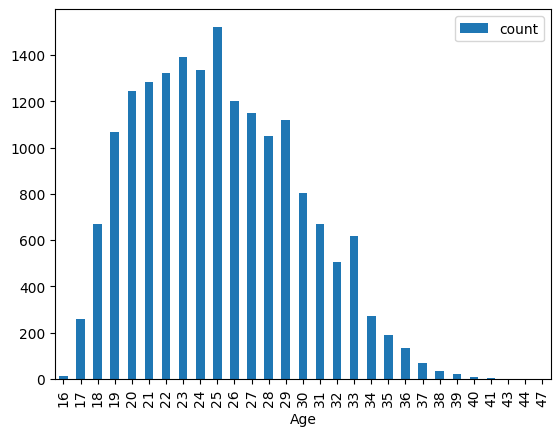

In [42]:
# Plot the number of players of each age as a bar chart.
import matplotlib.pyplot as plt

age_df.plot(x='Age', y='count', kind='bar')
plt.show()

The ages are in the order Spark returned them, so the chart is hard to read. `sort_values(by='age')` sorts the pandas DataFrame first.

**Expected:** a bell-shaped chart, rising from age 16 to a peak at 25 and falling to 47.

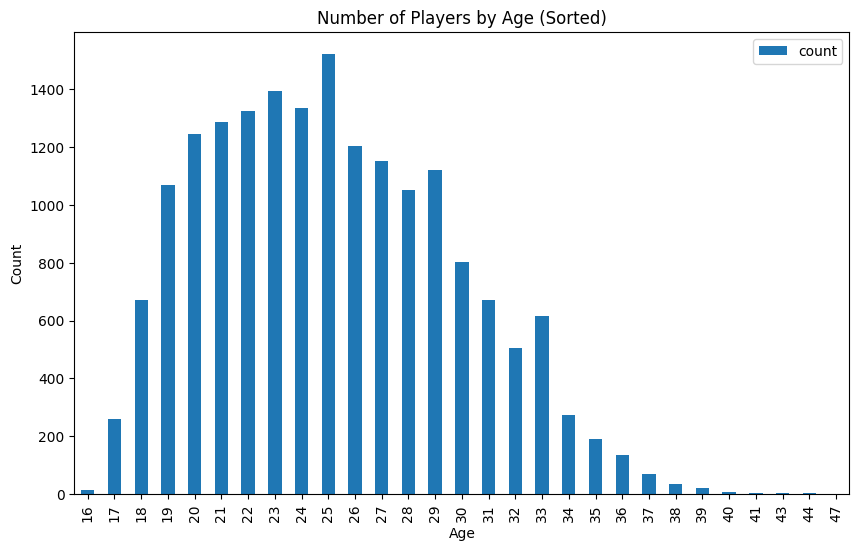

In [43]:
# Plot the same chart, sorted by age.
age_df_sorted = age_df.sort_values(by='Age')
age_df_sorted.plot(x='Age', y='count', kind='bar', figsize=(10, 6))
plt.title('Number of Players by Age (Sorted)')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

### 4.3 Query 3: Count the players in each club

In [44]:
# Count the players in each club.
spark.sql("""
    SELECT Club, COUNT(*) AS count
    FROM FifaView
    GROUP BY Club
""").show()

+--------------------+-----+
|                Club|count|
+--------------------+-----+
|             Palermo|   28|
|         Yeovil Town|   21|
|  1. FC Union Berlin|   27|
|  Santiago Wanderers|   20|
|               Carpi|   30|
|Evkur Yeni Malaty...|   30|
|          Sagan Tosu|   25|
|            FC Basel|   25|
|  Argentinos Juniors|   28|
|       Karlsruher SC|   27|
|  Lorca Deportiva CF|   29|
|     SC Paderborn 07|   28|
|     Cheltenham Town|   28|
|San Lorenzo de Al...|   28|
|         SC Freiburg|   32|
|  SpVgg Unterhaching|   28|
|Atletico Nacional...|   28|
|Universidad Católica|   20|
|         GFC Ajaccio|   25|
|           FC Luzern|   27|
+--------------------+-----+
only showing top 20 rows


### 4.4 Query 4: Clubs with more than 33 players

**Goal:** `HAVING` filters **groups** after `GROUP BY`, as `WHERE` filters rows before it. Spark names the unnamed count column `count(1)`.

**Expected:** Villarreal CF (35), seven clubs with 34 players, such as Manchester United and Borussia Dortmund, and a row `NULL` with 248 players.

In [45]:
# Count the players in each club and keep the clubs with more than 33.
spark.sql("""
    SELECT Club, COUNT(*) AS count
    FROM FifaView
    GROUP BY Club
    HAVING COUNT(*) > 33
""").show()

+------------------+-----+
|              Club|count|
+------------------+-----+
| Manchester United|   34|
|     UD Las Palmas|   34|
|              NULL|  248|
|Olympique Lyonnais|   34|
|     VfL Wolfsburg|   34|
|          OGC Nice|   34|
|     Villarreal CF|   35|
|         FC Nantes|   34|
| Borussia Dortmund|   34|
+------------------+-----+



The `NULL` row is not a club: it collects the **248 players with no club** (free agents), whose `Club` field is empty. `GROUP BY` treats all the empty values as one group. This is a reminder to check for missing values before trusting a result.

Show the result as a **pie chart**. `set_index('club')` uses the club names as the slice labels. The players without a club appear as `None` (a missing value), and make by far the biggest slice.

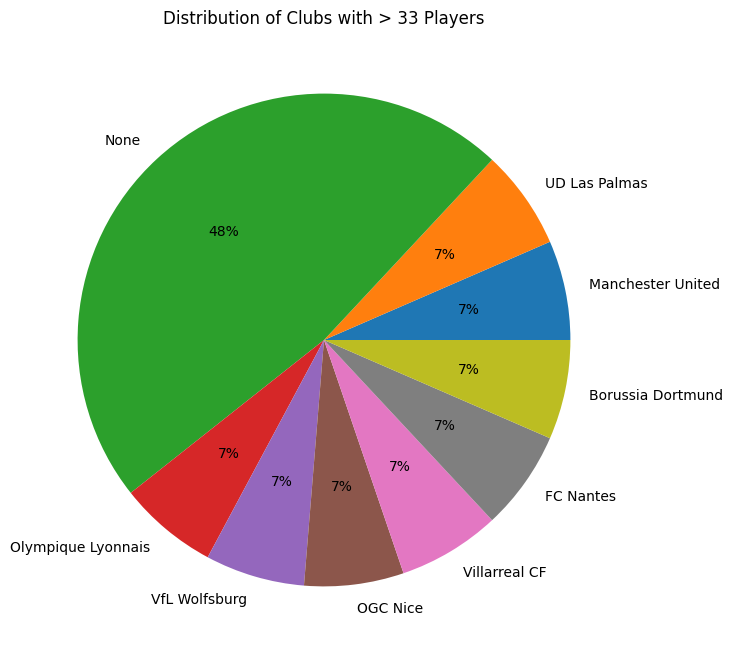

In [46]:
# Plot the clubs as a pie chart.
import matplotlib.pyplot as plt

# Query the clubs with more than 33 players and convert to a pandas DataFrame
club_df = spark.sql("""
    SELECT Club, COUNT(*) AS count
    FROM FifaView
    GROUP BY Club
    HAVING COUNT(*) > 33
""").toPandas()

# Set the club name as the index so they are used as labels on the chart
club_df.set_index('Club').plot(kind='pie', y='count', figsize=(8, 8), legend=False, autopct='%1.0f%%')
plt.ylabel('')  # Hide the default y-label 'count'
plt.title('Distribution of Clubs with > 33 Players')
plt.show()

**A cleaner query.** `WHERE club IS NOT NULL` removes the players without a club before grouping, `AS players` gives the count a readable name, and `ORDER BY` sorts the clubs. `autopct='%1.0f%%'` prints each slice's percentage.

In [47]:
# Clubs with more than 33 players, without the players who have no club.
spark.sql("""
    SELECT Club, COUNT(*) AS count
    FROM FifaView
    WHERE Club IS NOT NULL
    GROUP BY Club
    HAVING COUNT(*) > 33
""").show()

+------------------+-----+
|              Club|count|
+------------------+-----+
| Manchester United|   34|
|     UD Las Palmas|   34|
|Olympique Lyonnais|   34|
|     VfL Wolfsburg|   34|
|          OGC Nice|   34|
|     Villarreal CF|   35|
|         FC Nantes|   34|
| Borussia Dortmund|   34|
+------------------+-----+



### 4.5 SQL or DataFrame: the same plan

**Goal:** See that SQL and the DataFrame API are two ways of writing the same thing. The next two cells ask the same question, the average overall rating per club, one in SQL and one with DataFrame operations. `explain()` shows that Catalyst turns both into the **same physical plan**, so neither is faster: choose whichever is clearer.

In [53]:
# The question in SQL: show the plan.
spark.sql("""
    SELECT Club, AVG(Overall) as avg_overall
    FROM FifaView
    GROUP BY Club
""").explain()

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- HashAggregate(keys=[Club#25], functions=[avg(Overall#23)])
   +- Exchange hashpartitioning(Club#25, 200), ENSURE_REQUIREMENTS, [plan_id=1054]
      +- HashAggregate(keys=[Club#25], functions=[partial_avg(Overall#23)])
         +- FileScan csv [Overall#23,Club#25] Batched: false, DataFilters: [], Format: CSV, Location: InMemoryFileIndex(1 paths)[file:/content/CompleteDataset.csv], PartitionFilters: [], PushedFilters: [], ReadSchema: struct<Overall:int,Club:string>




In [54]:
# The same question with DataFrame operations: show the plan.
fifa_df.groupBy("Club").agg(F.avg("Overall").alias("avg_overall")).explain()

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- HashAggregate(keys=[Club#25], functions=[avg(Overall#23)])
   +- Exchange hashpartitioning(Club#25, 200), ENSURE_REQUIREMENTS, [plan_id=1067]
      +- HashAggregate(keys=[Club#25], functions=[partial_avg(Overall#23)])
         +- FileScan csv [Overall#23,Club#25] Batched: false, DataFilters: [], Format: CSV, Location: InMemoryFileIndex(1 paths)[file:/content/CompleteDataset.csv], PartitionFilters: [], PushedFilters: [], ReadSchema: struct<Overall:int,Club:string>




## 5. Additional exercises

**Goal:** Answer these questions on your own, in SQL (`spark.sql`) or with DataFrame operations. Use the empty cells below.

1. The 10 players with the highest `Overall` rating in **Manchester United**.
2. The **average age** of the players in each club, for clubs with more than 30 players, youngest first.
3. The **5 nationalities** with the most players rated 80 or more.
4. The 10 players with the biggest gap between `Potential` and `Overall` (the most room to improve).
5. A **bar chart** of the 10 most valuable clubs, using the `value_m` column from Step 3.6 (total value of all their players).

A worked example for question 1:

In [ ]:
# Example: the 10 best players in Manchester United.
spark.sql("""
    SELECT Name, Age, Overall, Potential
    FROM FifaView
    WHERE club = 'Manchester United'
    ORDER BY Overall DESC
    LIMIT 10""").show()

In [ ]:
# Q2: Average age of the players in each club with more than 30 players, youngest club first.


In [ ]:
# Q3: The 5 nationalities with the most players rated 80 or more (Overall >= 80).


In [ ]:
# Q4: The 10 players with the biggest gap between Potential and Overall (the most room to improve).


In [ ]:
# Q5: Bar chart of the 10 clubs whose players are worth the most in total (sum of value_m from Step 3.6).


## 6. Stop Spark

**Goal:** `spark.stop()` ends the SparkSession and frees its memory. The temporary view `FifaView` disappears with it. To continue working, run Step 1.3 again.

In [56]:
# Stop the SparkSession.
spark.stop()

## Check your understanding

1. Why can Spark be much faster than Hive on MapReduce for a job with several steps?
2. What is the difference between a **transformation** and an **action**? Give two examples of each from this lab.
3. Why did `Value`, `Wage` and `Acceleration` get the type `string` with `inferSchema=True`? What problems does this cause?
4. What does `toPandas()` do, and why should it only be used on small results?
5. What is the `NULL` club in Query 4, and how did the cleaner query handle it?
6. A colleague says the SQL version of a query is slower than the DataFrame version. How would you check, and what would you expect to find?